In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import os

In [3]:
files = os.listdir("uber-traffic")
files

['uber-raw-data-janjune-15.csv',
 'uber-raw-data-apr14.csv',
 'uber-raw-data-aug14.csv',
 'uber-raw-data-sep14.csv',
 'uber-raw-data-jul14.csv',
 'uber-raw-data-jun14.csv',
 'uber-raw-data-may14.csv']

In [4]:
files.remove("uber-raw-data-janjune-15.csv")
files

['uber-raw-data-apr14.csv',
 'uber-raw-data-aug14.csv',
 'uber-raw-data-sep14.csv',
 'uber-raw-data-jul14.csv',
 'uber-raw-data-jun14.csv',
 'uber-raw-data-may14.csv']

In [9]:
data1 = pd.read_csv("uber-traffic/uber-raw-data-apr14.csv")
data2 = pd.read_csv("uber-traffic/uber-raw-data-aug14.csv")
data3 = pd.read_csv("uber-traffic/uber-raw-data-sep14.csv")
data4 = pd.read_csv("uber-traffic/uber-raw-data-jul14.csv")
data5 = pd.read_csv("uber-traffic/uber-raw-data-jun14.csv")
data6 = pd.read_csv("uber-traffic/uber-raw-data-may14.csv")
hasil = pd.concat([data1, data2, data3, data4, data5, data6])
hasil

,Date/Time,Lat,Lon,Base
0,4/1/2014 0:11:00,40.7690,-73.9549,B02512
1,4/1/2014 0:17:00,40.7267,-74.0345,B02512
2,4/1/2014 0:21:00,40.7316,-73.9873,B02512
3,4/1/2014 0:28:00,40.7588,-73.9776,B02512
4,4/1/2014 0:33:00,40.7594,-73.9722,B02512
...,...,...,...,...
652430,5/31/2014 23:45:00,40.7309,-74.0014,B02764
652431,5/31/2014 23:52:00,40.7528,-73.9798,B02764
652432,5/31/2014 23:55:00,40.7158,-73.9519,B02764
652433,5/31/2014 23:56:00,40.6961,-73.8997,B02764


In [11]:
final = pd.DataFrame()

for file in files:
    df = pd.read_csv("uber-traffic/" + file)
    final = pd.concat([df,final])

final

,Date/Time,Lat,Lon,Base
0,5/1/2014 0:02:00,40.7521,-73.9914,B02512
1,5/1/2014 0:06:00,40.6965,-73.9715,B02512
2,5/1/2014 0:15:00,40.7464,-73.9838,B02512
3,5/1/2014 0:17:00,40.7463,-74.0011,B02512
4,5/1/2014 0:17:00,40.7594,-73.9734,B02512
...,...,...,...,...
564511,4/30/2014 23:22:00,40.7640,-73.9744,B02764
564512,4/30/2014 23:26:00,40.7629,-73.9672,B02764
564513,4/30/2014 23:31:00,40.7443,-73.9889,B02764
564514,4/30/2014 23:32:00,40.6756,-73.9405,B02764


In [12]:
final.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4534327 entries, 0 to 564515
Data columns (total 4 columns):
 #   Column     Dtype  
---  ------     -----  
 0   Date/Time  object 
 1   Lat        float64
 2   Lon        float64
 3   Base       object 
dtypes: float64(2), object(2)
memory usage: 173.0+ MB


In [14]:
final.columns

Index(['Date/Time', 'Lat', 'Lon', 'Base'], dtype='object')

In [15]:
df = final.copy()

df["Date/Time"] = pd.to_datetime(df["Date/Time"])
df

,Date/Time,Lat,Lon,Base
0,2014-05-01 00:02:00,40.7521,-73.9914,B02512
1,2014-05-01 00:06:00,40.6965,-73.9715,B02512
2,2014-05-01 00:15:00,40.7464,-73.9838,B02512
3,2014-05-01 00:17:00,40.7463,-74.0011,B02512
4,2014-05-01 00:17:00,40.7594,-73.9734,B02512
...,...,...,...,...
564511,2014-04-30 23:22:00,40.7640,-73.9744,B02764
564512,2014-04-30 23:26:00,40.7629,-73.9672,B02764
564513,2014-04-30 23:31:00,40.7443,-73.9889,B02764
564514,2014-04-30 23:32:00,40.6756,-73.9405,B02764


In [17]:
df["weekday"] = df["Date/Time"].dt.day_name()
df["day"] = df["Date/Time"].dt.day
df["minute"] = df["Date/Time"].dt.minute
df["month"] = df["Date/Time"].dt.month
df["hour"] = df["Date/Time"].dt.hour
df["year"] = df["Date/Time"].dt.year

df

,Date/Time,Lat,Lon,Base,weekday,day,minute,month,hour,year
0,2014-05-01 00:02:00,40.7521,-73.9914,B02512,Thursday,1,2,5,0,2014
1,2014-05-01 00:06:00,40.6965,-73.9715,B02512,Thursday,1,6,5,0,2014
2,2014-05-01 00:15:00,40.7464,-73.9838,B02512,Thursday,1,15,5,0,2014
3,2014-05-01 00:17:00,40.7463,-74.0011,B02512,Thursday,1,17,5,0,2014
4,2014-05-01 00:17:00,40.7594,-73.9734,B02512,Thursday,1,17,5,0,2014
...,...,...,...,...,...,...,...,...,...,...
564511,2014-04-30 23:22:00,40.7640,-73.9744,B02764,Wednesday,30,22,4,23,2014
564512,2014-04-30 23:26:00,40.7629,-73.9672,B02764,Wednesday,30,26,4,23,2014
564513,2014-04-30 23:31:00,40.7443,-73.9889,B02764,Wednesday,30,31,4,23,2014
564514,2014-04-30 23:32:00,40.6756,-73.9405,B02764,Wednesday,30,32,4,23,2014


In [22]:
jumlah = df["weekday"].value_counts().values
index = df["weekday"].value_counts().index

In [23]:
import plotly.express as px

px.bar(x = index, y = jumlah)

In [24]:
df["month"].unique()

array([5, 6, 7, 9, 8, 4], dtype=int32)

In [42]:
for i, data in enumerate(df["month"].unique(), 1):
    print(i, data)

1 5
2 6
3 7
4 9
5 8
6 4


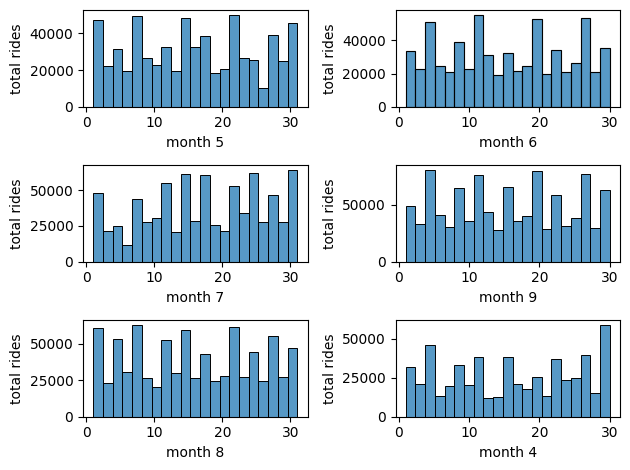

In [41]:
for i, data in enumerate(df["month"].unique(), 1):
    df_out = df[df["month"] == data]
    plt.subplot(3, 2, i)
    sns.histplot(df_out["day"], binwidth = 1.4)
    plt.xlabel(f"month {data}")
    plt.ylabel("total rides")
    plt.tight_layout()

<Axes: xlabel='hour', ylabel='Lat'>

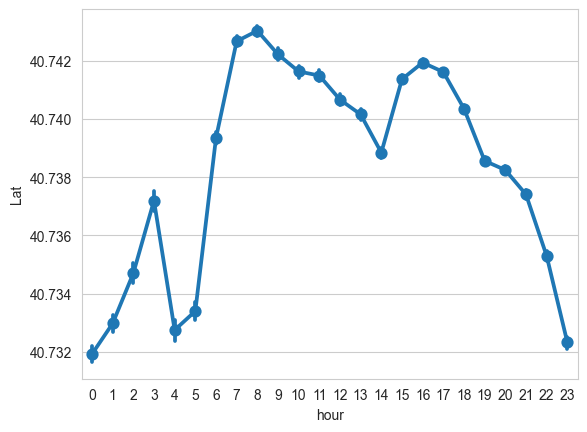

In [44]:
sns.set_style(style = "whitegrid")
sns.pointplot(x = "hour", y = "Lat", data = df)

<Axes: xlabel='hour', ylabel='Lat'>

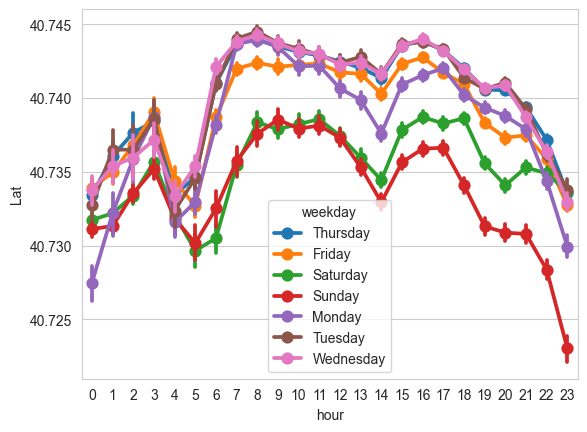

In [45]:
sns.pointplot(x = "hour", y = "Lat", hue = "weekday", data = df)

In [48]:
def hitung(a):
    return a + 1

data1 = pd.Series([1,2,3,4]).apply(hitung)
data2 = pd.Series([1,2,3,4]).apply(lambda a: a + 1)
data2

0    2
1    3
2    4
3    5
dtype: int64

In [50]:
by_cross = df.groupby(["weekday", "hour"]).apply(lambda a: len(a))
by_cross

/var/folders/q2/2h4p204s56d3vhv_jx5hmc6m0000gn/T/ipykernel_9785/3956277247.py:4: DeprecationWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.



weekday    hour
Friday     0       13716
           1        8163
           2        5350
           3        6930
           4        8806
                   ...  
Wednesday  19      47017
           20      47772
           21      44553
           22      32868
           23      18146
Length: 168, dtype: int64

In [58]:
test = by_cross.reset_index()
test.columns = ["weekday", "hour", "Count"]
test

,weekday,hour,Count
0,Friday,0,13716
1,Friday,1,8163
2,Friday,2,5350
3,Friday,3,6930
4,Friday,4,8806
...,...,...,...
163,Wednesday,19,47017
164,Wednesday,20,47772
165,Wednesday,21,44553
166,Wednesday,22,32868


In [59]:
pivot = by_cross.unstack()
pivot

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
weekday,,,,,,,,,,,,,,,,,,,,,
Friday,13716,8163,5350,6930,8806,13450,23412,32061,31509,25230,...,36206,43673,48169,51961,54762,49595,43542,48323,49409,41260
Monday,6436,3737,2938,6232,9640,15032,23746,31159,29265,22197,...,28157,32744,38770,42023,37000,34159,32849,28925,20158,11811
Saturday,27633,19189,12710,9542,6846,7084,8579,11014,14411,17669,...,31418,38769,43512,42844,45883,41098,38714,43826,47951,43174
Sunday,32877,23015,15436,10597,6374,6169,6596,8728,12128,16401,...,28151,31112,33038,31521,28291,25948,25076,23967,19566,12166
Thursday,9293,5290,3719,5637,8505,14169,27065,37038,35431,27812,...,36699,44442,50560,56704,55825,51907,51990,51953,44194,27764
Tuesday,6237,3509,2571,4494,7548,14241,26872,36599,33934,25023,...,34846,41338,48667,55500,50186,44789,44661,39913,27712,14869
Wednesday,7644,4324,3141,4855,7511,13794,26943,36495,33826,25635,...,35148,43388,50684,55637,52732,47017,47772,44553,32868,18146


In [60]:
balik = pivot.stack()
balik

weekday    hour
Friday     0       13716
           1        8163
           2        5350
           3        6930
           4        8806
                   ...  
Wednesday  19      47017
           20      47772
           21      44553
           22      32868
           23      18146
Length: 168, dtype: int64

<Axes: xlabel='hour', ylabel='weekday'>

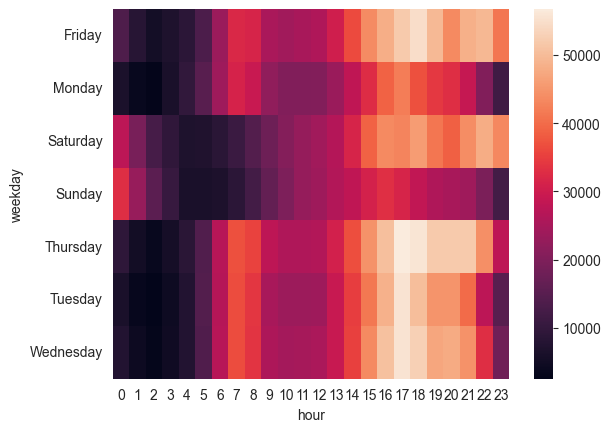

In [63]:
sns.heatmap(pivot)

In [73]:
from folium.plugins import HeatMap
import folium

basemap = folium.Map()
basemap

In [74]:
sunday = df[df["weekday"] == "Sunday"]
out = sunday.groupby(["Lat", "Lon"])["weekday"].count().reset_index()
HeatMap(out).add_to(basemap)
basemap